In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from utils import load_data

In [ ]:
DATASET_DIR = Path('/path/to/HYPERVIEW2/') # Specify the dir where data (train/ and test/ folders) are stored
X_train_dict, X_test_dict, y_train, _, _ = load_data(reductions=[], DATASET_DIR=DATASET_DIR)

# Visualize the ground truth

In [ ]:
# Load the ground truth measurements
DATASET_DIR = Path('/path/to/HYPERVIEW2')
GT_TRAIN_CSV_PATH = DATASET_DIR / 'train_gt.csv'
gt_train_df = pd.read_csv(GT_TRAIN_CSV_PATH)
gt_train_df.head()
column_names = ['Fe', 'Zn', 'B', 'Cu', 'S', 'Mn']
y_train_all = gt_train_df[column_names].values

In [4]:
gt_train_df

,sample_index,B,Cu,Zn,Fe,S,Mn
0,0,0.8,2.1,5.0,186.6,12.078640,110.7
1,1,0.6,3.5,7.3,255.6,12.199673,75.7
2,2,0.5,2.1,2.3,204.0,65.882013,87.1
3,3,0.8,1.9,3.3,165.6,31.942712,56.0
4,4,0.5,2.4,5.8,419.9,35.970698,65.1
...,...,...,...,...,...,...,...
1871,1871,0.6,2.6,2.6,225.4,31.778477,99.9
1872,1872,0.5,2.4,3.0,204.2,30.832575,94.2
1873,1873,0.6,2.6,6.1,298.9,10.246492,64.3
1874,1874,0.8,1.8,6.0,184.6,10.098610,125.3


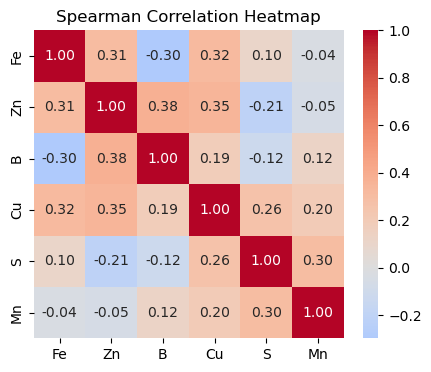

In [7]:
# Calculate the Spearman correlation matrix
spearman_corr_matrix = gt_train_df[column_names].corr(method='spearman')
# Plot the heatmap
plt.figure(figsize=(5, 4))
sns.heatmap(spearman_corr_matrix, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Spearman Correlation Heatmap')
plt.savefig("Figures/targets_correlation.png", dpi=300)
plt.show()

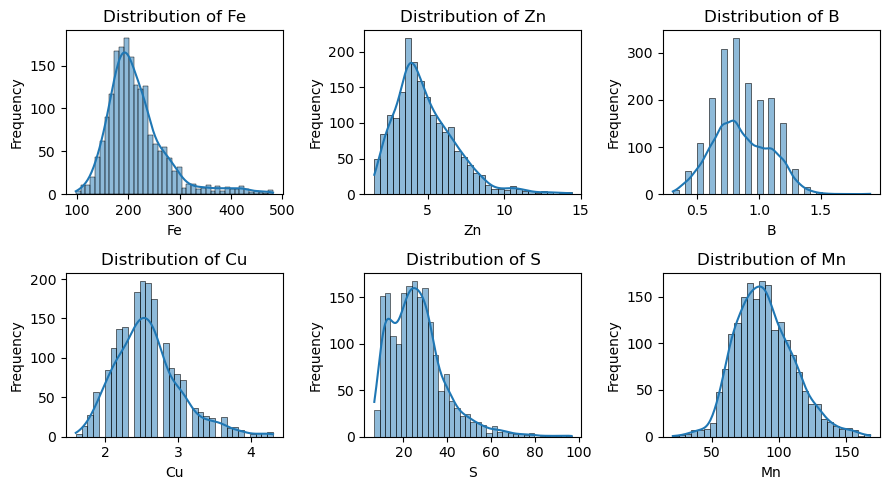

In [ ]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(9, 5))
axes = axes.flatten()

for ax, column in zip(axes, column_names):
    sns.histplot(gt_train_df[column], kde=True, ax=ax)
    ax.set_title(f'Distribution of {column}')
    ax.set_xlabel(column)
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.savefig("Figures/Targets_values_distribution.png", dpi=300)
plt.show()

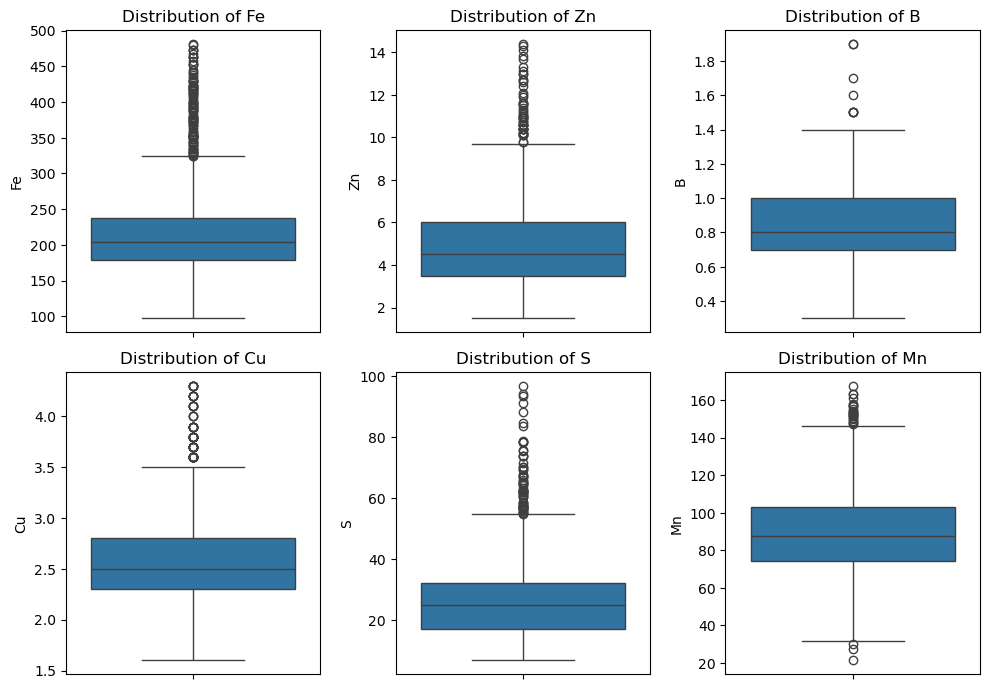

In [ ]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(10, 7))
axes = axes.flatten()
for ax, column in zip(axes, column_names):
    sns.boxplot(y=gt_train_df[column], ax=ax)
    ax.set_title(f'Distribution of {column}')
    ax.set_ylabel(column)
plt.tight_layout()
plt.show()

**Sampling strategy for Hyperview (1)**:
"Each field was divided into a sampling area with a spatial resolution ranging from 0.5 ha to 4 ha, and 12 soil samples were acquired on every sampling area in the Zig-Zag or Circle approach. Afterwards, they were mixed together and analyzed in the laboratory setting"

Therefore, we are predicting the **mean** target value per field.

# Visualize the input data

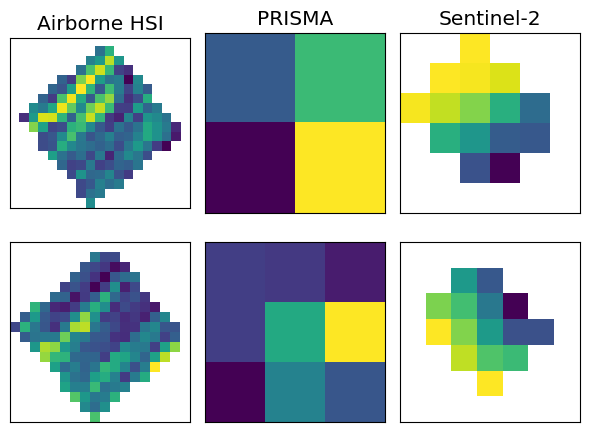

In [39]:
band = 0

modalities = ['hsi_airborne', 'hsi_satellite', 'msi_satellite']
modalities_names = {'hsi_airborne': "Airborne HSI", 'hsi_satellite': "PRISMA", 'msi_satellite': "Sentinel-2"}

fig, axs = plt.subplots(2, 3, figsize=(6, 4.7))  # Create a 10x3 subplot grid

bands = [46, 21, 2]

for image_idx in range(2):
    for i, modality in enumerate(modalities):
        arr = X_train_dict[modality][image_idx+8]
        axs[image_idx, i].imshow(arr[bands[i], :, :])
        axs[0, i].set_title(modalities_names[modality], fontsize=14.5)
        axs[image_idx, i].set_xticks([])
        axs[image_idx, i].set_yticks([])

plt.tight_layout()
plt.savefig("Figures/modalities_patches_examples.png", dpi=300)
plt.show()

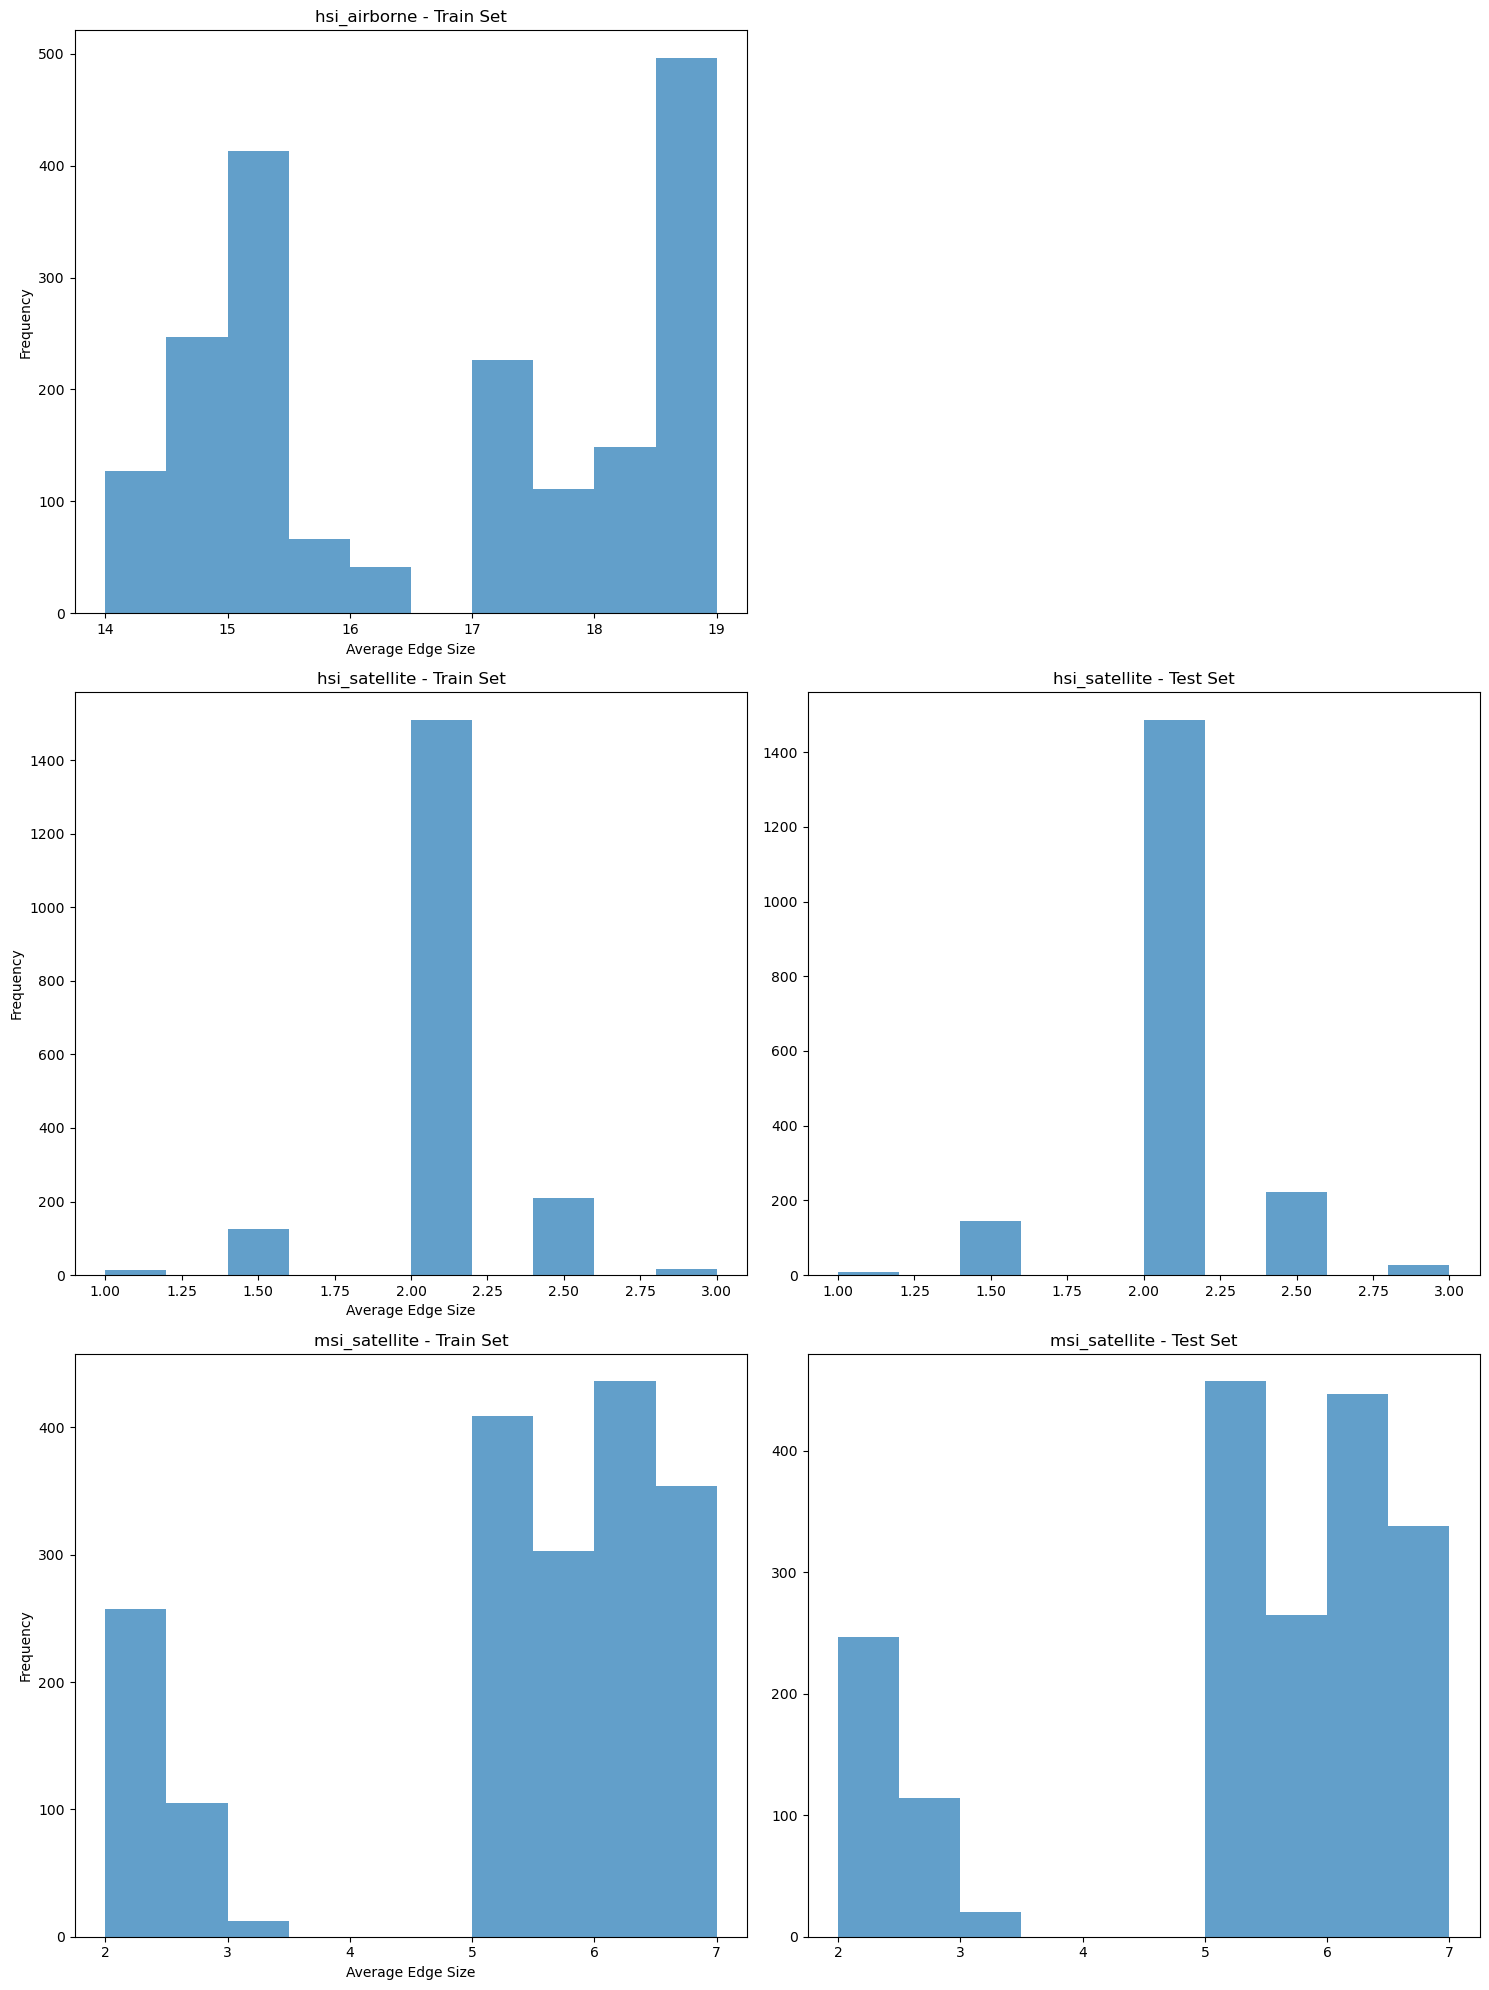

In [ ]:
# Calculate average edge size for each field
def calculate_average_edges(image_list):
    return [(img.shape[1] + img.shape[2]) / 2 for img in image_list]

# Create dictionaries of average edge sizes for train and test sets
train_avg_edge_sizes = {key: calculate_average_edges(value) for key, value in X_train_dict.items()}
test_avg_edge_sizes = {key: calculate_average_edges(value) for key, value in X_test_dict.items()}

# Plotting the distributions
fig, axs = plt.subplots(len(X_train_dict), 2, figsize=(15, 20))

categories = list(train_avg_edge_sizes.keys())

for i, category in enumerate(categories):
    # Train set distribution
    train_avg_edges = train_avg_edge_sizes[category]
    axs[i, 0].hist(train_avg_edges, bins=10, alpha=0.7)
    axs[i, 0].set_title(f'{category} - Train Set')
    axs[i, 0].set_xlabel('Average Edge Size')
    axs[i, 0].set_ylabel('Frequency')

    # Test set distribution
    if category in test_avg_edge_sizes:
        test_avg_edges = test_avg_edge_sizes[category]
        axs[i, 1].hist(test_avg_edges, bins=10, alpha=0.7)
        axs[i, 1].set_title(f'{category} - Test Set')
    else:
        # If no corresponding test data, leave the subplot empty
        axs[i, 1].axis('off')

plt.tight_layout()
plt.show()

## Correlation between wavelengths and target variables

In [10]:
X_train_dict, X_test_dict, y_train, n_valid_pixels_train_dict, n_valid_pixels_test_dict = load_data(reductions=['mean'])
train_feature_n_pixels_hsi = np.array(n_valid_pixels_train_dict['hsi_satellite'])
test_feature_n_pixels_hsi = np.array(n_valid_pixels_test_dict['hsi_satellite'])

train_feature_n_pixels_msi = np.array(n_valid_pixels_train_dict['msi_satellite'])
test_feature_n_pixels_msi = np.array(n_valid_pixels_test_dict['msi_satellite'])

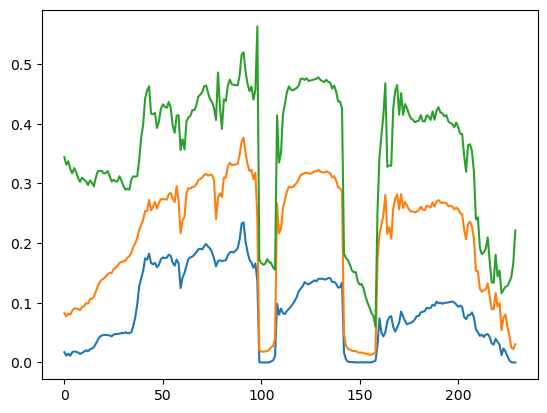

In [11]:
X_train_hsi_satellite = np.array(X_train_dict['hsi_satellite']) # shape is (1876, 230)

plt.plot(np.min(X_train_hsi_satellite, axis=0))
plt.plot(np.mean(X_train_hsi_satellite, axis=0))
plt.plot(np.max(X_train_hsi_satellite, axis=0))

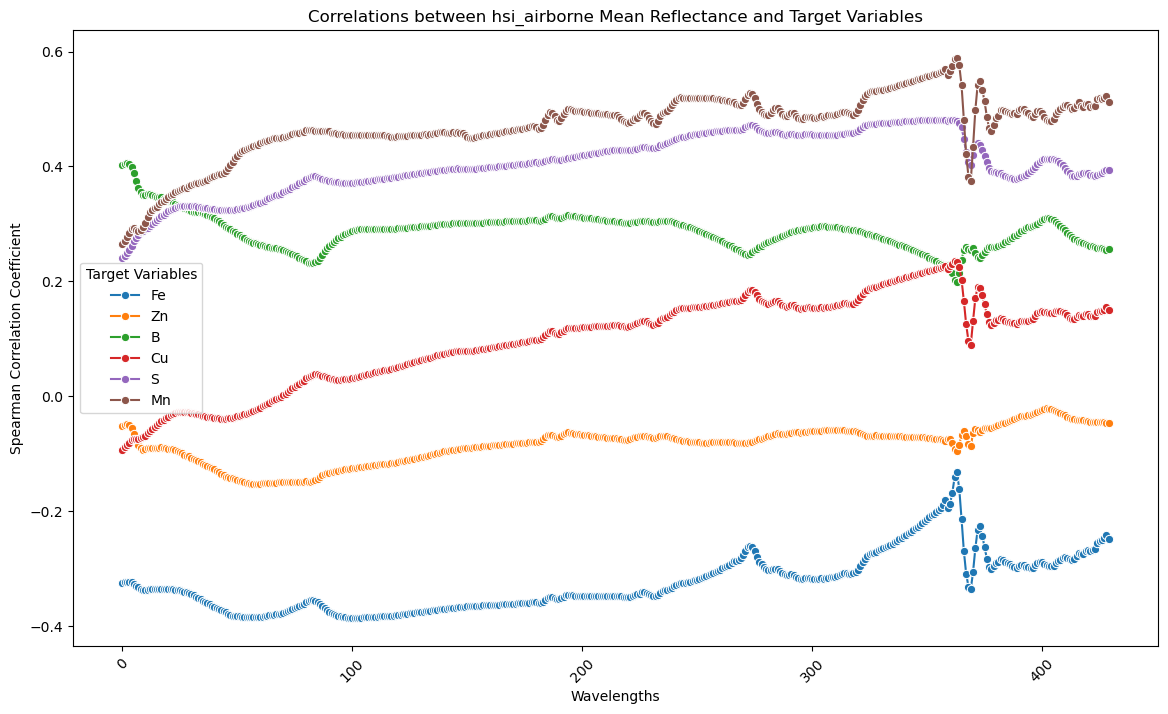

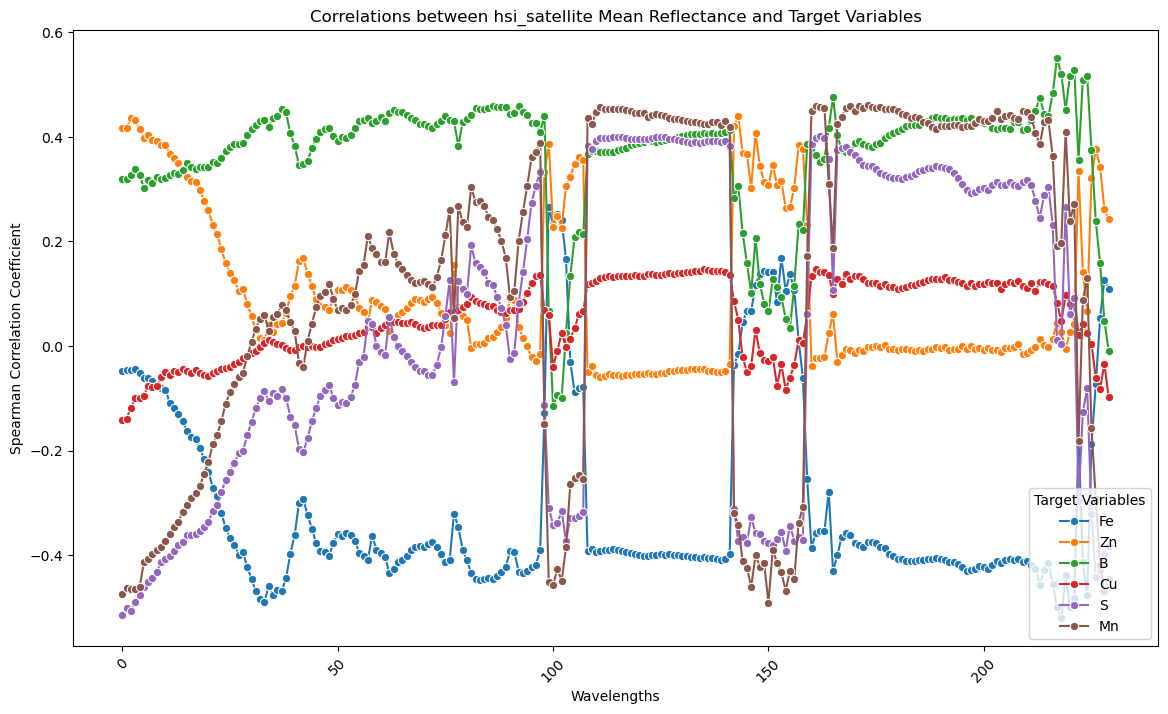

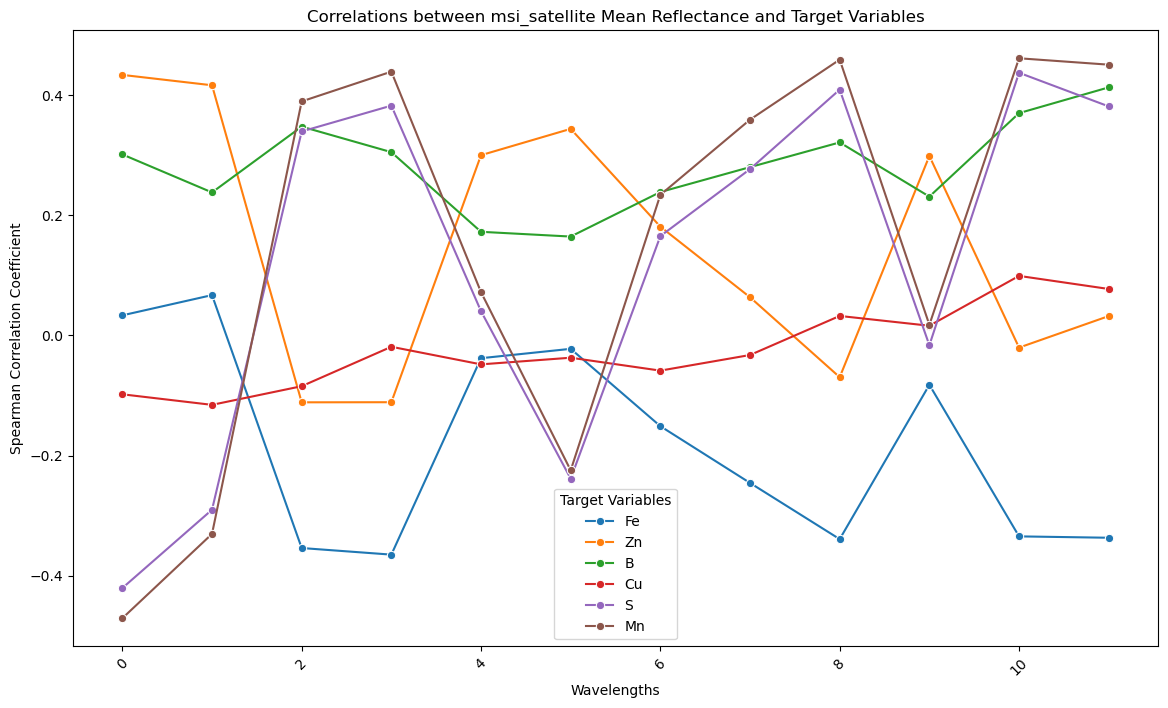

In [ ]:
modalities = ['hsi_airborne', 'hsi_satellite', 'msi_satellite']
y_train_df = pd.DataFrame(y_train)

# Iterate over each modality to compute and plot correlations with target variables
for i, modality in enumerate(modalities):
    # Get the mean reflectance values for the current modality
    X_modality_df = pd.DataFrame(X_train_dict[modality])

    # Initialize DataFrames to hold correlation results
    wavelength_corr = {col: [] for col in y_train_df.columns}

    # Calculate correlations between each wavelength and target variables
    for wavelength_index in range(X_modality_df.shape[1]):
        corr_values = y_train_df.corrwith(pd.Series(X_modality_df.iloc[:, wavelength_index]), method='spearman')
        for col in y_train_df.columns:
            wavelength_corr[col].append(corr_values[col])

    # Convert correlation results to a DataFrame
    wavelength_corr_df = pd.DataFrame(wavelength_corr, index=X_modality_df.columns)

    # Plot the correlation line for each target variable
    plt.figure(figsize=(14, 8))

    for idx, target_variable in enumerate(y_train_df.columns):
        sns.lineplot(x=wavelength_corr_df.index, y=wavelength_corr_df[target_variable], marker='o', label=column_names[idx])

    plt.title(f'Correlations between {modality} Mean Reflectance and Target Variables')
    plt.xlabel('Wavelengths')
    plt.ylabel('Spearman Correlation Coefficient')
    plt.xticks(rotation=45)
    plt.legend(title='Target Variables')
    plt.show()